# Figure 1

Overview of the curated *Escherichia coli* ALE mutation dataset. All panels are drawn on one canvas in the last cell, and every count is computed from the inputs below.

- **A** (`axA`): QC funnel, the number of mutation records retained at each step.
- **B**: dataset scale (`axB`, upper) and mutation spectrum (`axC`, lower), on one shared log axis.
- **C** (`axD`, `axDt`, `axDr`): number of mutated genes against number of endpoints, one point per experiment, with marginal histograms.
- **D** (`axF`): the ten most recurrently mutated genes, ranked by the number of experiments they are mutated in.
- **E** (`axG`): the 20 most represented condition categories, plus "Other".
- **F** (`axE`): mutated genes per endpoint in each experiment with at least two endpoints, as box plots.

Inputs: `data/qc/ecoli/qc_mutations.tsv`, `data/qc/ecoli/qc_pipeline_report.tsv` and `data/qc/ecoli/checkpoints/02_select_species_summary.json`. The experiments whose mutation data are not public have no rows in `qc_mutations.tsv`. For them, the figure reads `gene_by_endpoint.tsv`, `endpoints.tsv` and `mutation_types.tsv` in `data/qc/ecoli/nonpublic/`.

Output: `figures/Figure_1/Figure_1.svg` and `figures/Figure_1/Figure_1.png`.

Environment A. The final layout is set in Adobe Illustrator.

In [1]:
# %% Imports and shared style
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch

# Keep SVG text editable (Illustrator / Inkscape), embed fonts in PDF.
mpl.rcParams["svg.fonttype"] = "none"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["figure.facecolor"] = "white"
mpl.rcParams["axes.facecolor"] = "white"
# Text is set in Arial or Helvetica. Where neither is installed, matplotlib renders the PNG
# with its own DejaVu Sans, which is wider than Arial. The SVG is rewritten to Arial in the
# last cell, so it opens with the correct font in Illustrator.
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
mpl.rcParams["axes.spines.top"] = False
mpl.rcParams["axes.spines.right"] = False

# Manuscript palette. One data color is used across every panel except the funnel
# (whose three colors encode input / filtering / final and therefore carry meaning).
# DATA and ACCENT stay distinct against white, in grayscale and for color-blind readers, so
# the threshold and median lines remain visible in black-and-white print.
INK, FAINT = "#000000", "#d7dbe0"     # ALL text is black
DATA       = "#6B8299"     # every data mark: bars, points, box fills
DATA_LIGHT = "#B7C2CD"     # light tint: marginal histograms
DATA_EDGE  = "#41505E"     # outlines on filled marks
ACCENT     = "#8B2635"     # semantic lines only: threshold, medians
FUNNEL     = {"start": "#3a7ab8", "filter": "#a8b2bd", "final": "#2f8f4e"}

# Folders. The notebook runs from code/, so the folder above it holds data/, cache/ and figures/.
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"            # pipeline outputs (the results/ folder of ale-cooccurrence-mutual-exclusivity-nf)
# What the figure uses of the experiments whose mutation data are not public. These files belong to
# this folder, so they are read from here also when DATA_DIR points to another run.
NONPUB_DIR = ROOT / "data/qc/ecoli/nonpublic"
FIG_DIR = ROOT / "figures/Figure_1"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"data folder not found: {DATA_DIR}")
if not (ROOT / "code/Figure_1.ipynb").is_file():
    raise FileNotFoundError(f"run this notebook from the code/ folder (working folder: {Path.cwd()})")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SAVE = True          # write the SVG + PNG
DPI = 300

# All text (axis labels, tick labels, annotations) is pure black.
mpl.rcParams["text.color"] = INK
mpl.rcParams["axes.labelcolor"] = INK
mpl.rcParams["xtick.color"] = INK
mpl.rcParams["ytick.color"] = INK

# ---------------------------------------------------------------------------
# FONT SIZES (pt): every text element in every panel reads from here.
# Change one number to restyle that element across the whole figure.
# FONT_SCALE multiplies all of them at once (e.g. 1.2 to enlarge everything).
# ---------------------------------------------------------------------------
FONT_SCALE = 1.0

FS = {
    "axis_title":   14,   # x / y axis titles
    "tick":         14,   # numeric tick labels
    "category":     14,   # y-axis category names (gene names, mutation types, scale rows)
    "value":        14,   # counts printed beside bars
    "legend":       14,   # legend entries
    "annotation":   14,   # in-plot notes (threshold label, endpoint keys)
    "funnel_stage": 14,   # funnel stage names
    "funnel_value": 14,   # funnel counts
    "panel_label":  24,   # panel letters A to F (bold)
}
FS = {k: v * FONT_SCALE for k, v in FS.items()}


In [2]:
# %% Load everything ONCE, and derive every table the panels need.

# --- final cleaned mutation table (the analysis input) ---
df = pd.read_csv(DATA_DIR / "qc/ecoli/qc_mutations.tsv", sep="\t", low_memory=False)

# --- the experiments whose mutation data are not public (no rows in df) ---
nonpub_cells = pd.read_csv(NONPUB_DIR / "gene_by_endpoint.tsv", sep="\t")  # genes mutated per endpoint
nonpub_eps = pd.read_csv(NONPUB_DIR / "endpoints.tsv", sep="\t")           # one row per endpoint
nonpub_types = pd.read_csv(NONPUB_DIR / "mutation_types.tsv", sep="\t")    # mutations per type
_key = ["exp", "sample_endpoint"]
_both = sorted(set(df["exp"]) & set(nonpub_eps["exp"]))
if _both:
    raise ValueError(f"experiments both in qc_mutations.tsv and in {NONPUB_DIR}: {_both}")
if (nonpub_cells.isna().any().any() or nonpub_types.isna().any().any()
        or nonpub_eps[_key].isna().any().any()):
    raise ValueError(f"empty values in the files of {NONPUB_DIR}")
if (nonpub_eps.duplicated(_key).any()
        or set(map(tuple, nonpub_cells[_key].values)) != set(map(tuple, nonpub_eps[_key].values))
        or set(nonpub_types["exp"]) != set(nonpub_eps["exp"])):
    raise ValueError(f"the files of {NONPUB_DIR} do not list the same experiments and endpoints")

# --- genes, endpoints and condition of every experiment, for the counts below ---
# One row per mutation for the experiments in df, one row per mutated gene per endpoint for the
# others. Only distinct values, and the first condition of each experiment, are read from it.
# Mutation counts come from df and nonpub_types.
cells = pd.concat(
    [df[_key + ["Gene_name_normalized", "Condition_normalized"]],
     nonpub_cells[_key + ["Gene_name_normalized"]].merge(
         nonpub_eps[_key + ["Condition_normalized"]], on=_key, validate="many_to_one")],
    ignore_index=True)

# --- QC report + step-02 checkpoint (drive the funnel, no hardcoded counts) ---
report = pd.read_csv(DATA_DIR / "qc/ecoli/qc_pipeline_report.tsv", sep="\t").set_index("step_id")
ckpt02 = json.load(open(DATA_DIR / "qc/ecoli/checkpoints/02_select_species_summary.json"))

# The funnel starts at the E. coli records of the export. Step 01 loads every species, and
# step 02 removes the other species and the untreated condition in one step, so the E. coli
# count is derived from the step-02 checkpoint.
n_ecoli_muts = ckpt02["n_rows_before"] - ckpt02["n_removed_non_ecoli"]

# --- Panel A: funnel counts (the stage names drawn are FUNNEL_LABELS in the last cell) ---
funnel = pd.DataFrame([
    ("Raw ALEdb export\n(E. coli)",            int(n_ecoli_muts),                  "start"),
    ("Untreated condition removed",             int(report.loc[2, "n_rows_after"]), "filter"),
    ("Starting-strain mutations removed",       int(report.loc[3, "n_rows_after"]), "filter"),
    ("Hypermutators, burden & frequency\nfiltering; endpoint extraction",
                                                int(report.loc[4, "n_rows_after"]), "filter"),
    ("Gene names normalized",                   int(report.loc[5, "n_rows_after"]), "filter"),
    ("Specific experiments removed",            int(report.loc[6, "n_rows_after"]), "final"),
], columns=["stage", "mutations", "kind"])
funnel["removed"] = (funnel["mutations"].shift(1) - funnel["mutations"]).astype("Int64")

# --- per-experiment scale (Panel C) ---
per_exp = cells.groupby("exp").agg(
    endpoints=("sample_endpoint", "nunique"),
    genes=("Gene_name_normalized", "nunique"),
)
per_exp["mutations"] = pd.concat([df.groupby("exp").size(),
                                  nonpub_types.groupby("exp")["n_mutations"].sum()])
MIN_ENDPOINTS = 2                                  # min_endpoints in the pipeline's analysis config
per_exp["analyzable"] = per_exp["endpoints"] >= MIN_ENDPOINTS

# --- per-endpoint burden (Panel F) ---
# Burden = number of MUTATED GENES per endpoint, i.e. the column marginal of the binary
# matrix. DISCOVER's background model matches this quantity in expectation (its input is
# binary, so a gene mutated ten times contributes 1). NOT the raw mutation-call count.
burden = (cells.groupby(["exp", "sample_endpoint"])["Gene_name_normalized"]
           .nunique().rename("burden").reset_index())

# --- gene recurrence (Panel D) ---
gene_freq = cells.groupby("Gene_name_normalized")["sample_endpoint"].nunique().sort_values(ascending=False)

# --- Panel B: headline numbers ---
scale = pd.Series({
    "mutations":            len(df) + int(nonpub_types["n_mutations"].sum()),
    "genes":                cells["Gene_name_normalized"].nunique(),
    "endpoints (strains)":  cells["sample_endpoint"].nunique(),
    "experiments":          cells["exp"].nunique(),
    f"analyzable experiments\n(>= {MIN_ENDPOINTS} endpoints)": int(per_exp["analyzable"].sum()),
})

print("Loaded and derived. Headline numbers:")
for k, v in scale.items():
    print(f"  {k.replace(chr(10), ' '):42s} {v:,}")


Loaded and derived. Headline numbers:
  mutations                                  8,002
  genes                                      2,152
  endpoints (strains)                        929
  experiments                                171
  analyzable experiments (>= 2 endpoints)    141


wrote figures/Figure_1/Figure_1.svg  (20.68 x 11.22 in)


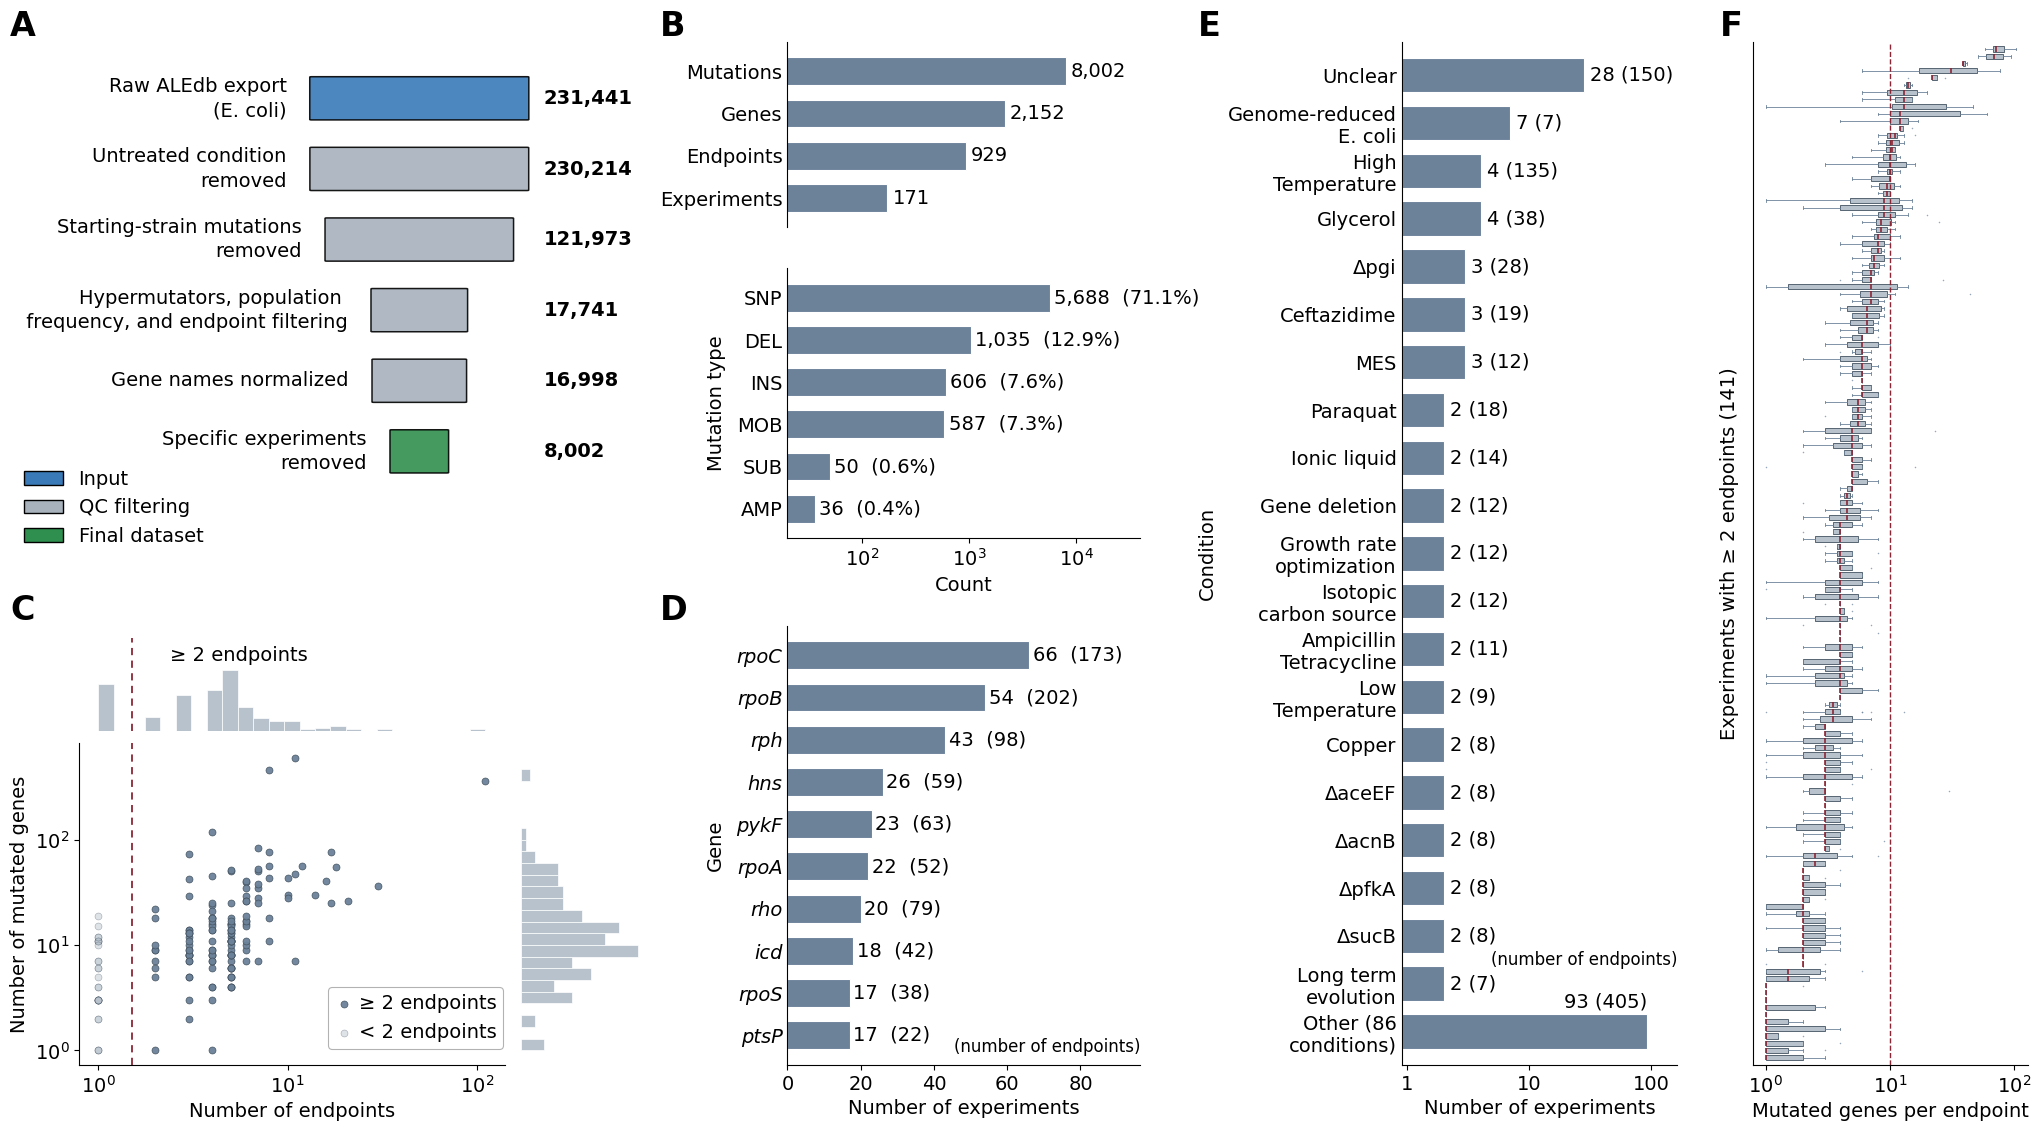

In [3]:
# %% Combined figure: all six panels on ONE canvas
#
# Why one canvas rather than stitched panel SVGs: every text element here is set in the same
# absolute point size (the FS dict) and nothing is rescaled afterwards, so the typography is
# consistent across panels by construction. Assembling separately-sized SVGs in a vector
# editor scales each panel by a different factor, which is what makes fonts drift apart.
#
#   +---------------+-------------+------+-------+   F is drawn HORIZONTALLY
#   |   A  funnel   |  B  scale   |      |       |   (vert=False), so it becomes a tall
#   |               +-------------+      |   F   |   strip. That is what lets all four
#   +---------------+  B  spectrum|   E  |       |   columns run the full height with no
#   |               +-------------+ cond.| burden|   dead space. B and D split the
#   |  C  exp.scale |             |      |       |   middle column evenly. B's scale and
#   |   (dot plot)  |  D  conv.   |      |       |   spectrum share ONE log x-axis
#   +---------------+-------------+------+-------+   titled "Count".
#
# Panel letters A to F are drawn at the end of this cell, above the panels.

# COL23_GAP adds space between the middle column and axG WITHOUT resizing any panel: the
# canvas grows by exactly that amount, the gridspec is pinned to the same absolute inches
# it would occupy on a BASE_W canvas (so every column keeps its width), and axG and axE are
# then slid right into the new room. BASE_W is the width the gridspec margins are given for.
BASE_W = 19.83
COL23_GAP = 0.85             # inches of extra clearance between column 2 and axG
# LETTER_BAND works the same way in height: the canvas grows by that many inches at the top,
# where the top row of panel letters sits, and the gridspec keeps the inches it has on a
# BASE_H canvas, so no panel moves or changes size.
BASE_H = 11
LETTER_BAND = 0.22           # inches added above the panels for the top row of letters
FIG_W, FIG_H = BASE_W + COL23_GAP, BASE_H + LETTER_BAND
WSPACE = 0.30         # gap between the four columns. Too small a gap makes the labels
                       # drawn outside the axes collide.
FUNNEL_INDENT = 0.10   # inches the funnel's ink sits RIGHT of the dot plot's ink
MID_GAP = 0.23         # vertical gap in the middle column, between the axB+axC block and axF.
D_ENDPOINT_MIN = 2     # panel C (axD): pairwise-testing cut-off
                       # (min_endpoints in the pipeline's analysis config)
E_ENDPOINT_MIN = 2     # panel F (axE): same cut-off as C, so F shows exactly the
                       # analyzed experiments
D_LEGEND_XY = (1.02, 0.02)   # panel C (axD) legend anchor, axes coords (x, y).
                             # x: 1.00 = flush with right spine, >1 pushes outside, <1 pulls in.
                             # y: 0.02 = just above the bottom spine, raise to lift it.

fig = plt.figure(figsize=(FIG_W, FIG_H))
# wspace is wide on purpose: axB's and axC's y-tick labels and axE's rotated y-title are
# drawn OUTSIDE their axes, and axC's value labels overflow to the right of theirs.
# `left` reserves room for axD's y-axis, `bottom` for the x-axis titles.
# axG and axE are matched in drawn width: axG's column carries the 0.62 in label gutter and
# axE's is grown 0.38 in on the left, so the ratios differ by ~1.0 to land at the same
# axes width.
outer = fig.add_gridspec(1, 4, width_ratios=[5.6, 3.8, 3.35, 2.35], wspace=WSPACE,
                         left=0.048 * BASE_W / FIG_W, right=0.988 * BASE_W / FIG_W,
                         top=0.985 * BASE_H / FIG_H, bottom=0.055 * BASE_H / FIG_H)

lcol = outer[0].subgridspec(2, 1, height_ratios=[6.0, 5.0], hspace=0.18)
axA = fig.add_subplot(lcol[0])
dgs = lcol[1].subgridspec(2, 2, width_ratios=[4, 1.15], height_ratios=[1.15, 4],
                          wspace=0.06, hspace=0.06)
axD = fig.add_subplot(dgs[1, 0])
axDt = fig.add_subplot(dgs[0, 0], sharex=axD)
axDr = fig.add_subplot(dgs[1, 1], sharey=axD)

# axB, axC and axF must end up with IDENTICAL bar thickness. Thickness = 0.66 x (axes
# height / y-span), and their y-spans are 4.4, 6.4 and 10.4 units, so their axes heights
# have to be in that same ratio. axB+axC are nested one level deeper (their shared-axis gap
# stays tight at 0.10 while the drop to axF is MID_GAP, wide enough for axC's "Count"
# title), and that inner gap eats height from the axB+axC block, hence 11.33 rather than
# 10.8 for the block's share.
mcol = outer[1].subgridspec(2, 1, height_ratios=[11.33, 10.4], hspace=MID_GAP)
bc = mcol[0].subgridspec(2, 1, height_ratios=[4.4, 6.4], hspace=0.10)
axB = fig.add_subplot(bc[0])
axC = fig.add_subplot(bc[1], sharex=axB)
axF = fig.add_subplot(mcol[1])

axG = fig.add_subplot(outer[2])
axE = fig.add_subplot(outer[3])

# axG's wrapped condition names are drawn OUTSIDE its axes, to the left, where they would
# run into axC's and axF's value labels. Widening WSPACE would open every column gap, so
# instead axG's plotting box is inset on its LEFT only, keeping its right edge (and so the
# gap to axE) untouched.
# Slide axG and axE right into the room COL23_GAP opens. Widths are untouched.
_cg = COL23_GAP / FIG_W
for _ax in (axG, axE):
    _p = _ax.get_position()
    _ax.set_position([_p.x0 + _cg, _p.y0, _p.width, _p.height])

G_LABEL_GUTTER = 0.62        # inches inset on axG's left: room for its category names, and
                             # it opens the gap to the middle column at the same time
_gp = axG.get_position()
_gd = G_LABEL_GUTTER / FIG_W
axG.set_position([_gp.x0 + _gd, _gp.y0, _gp.width - _gd, _gp.height])

# Drop the spectrum panel away from the scale panel above it. Done as a SHIFT, not by
# raising the bc hspace: hspace would resize axB and axC, and their heights are what keep
# bar thickness matched with axF. Shifting moves axC without changing its height, spending
# the clearance below it instead (MID_GAP still leaves room before axF).
C_DROP = 0.18                # inches axC moves down, away from axB
_cp = axC.get_position()
axC.set_position([_cp.x0, _cp.y0 - C_DROP / FIG_H, _cp.width, _cp.height])

# Open the column-1 -> column-2 gap by insetting axB, axC and axF on their left. Their
# category names are drawn outside the axes, so moving the boxes right moves the names right
# too and widens the clearance from axA's counts and axD's right-hand histogram. Applied to
# all three together so axB, axC and axF stay mutually aligned.
MID_LEFT_INSET = 0.30        # inches the middle column moves away from the first
_md = MID_LEFT_INSET / FIG_W
for _ax in (axB, axC, axF):
    _mp = _ax.get_position()
    _ax.set_position([_mp.x0 + _md, _mp.y0, _mp.width - _md, _mp.height])

# Close some of the axG -> axE gap by growing axE leftwards. Done on axE rather than by
# shrinking WSPACE, which is shared by all four columns, and it hands the extra width to the
# boxplot.
E_GROW_LEFT = 0.38           # inches axE's left edge moves toward axG
_ep = axE.get_position()
_ed = E_GROW_LEFT / FIG_W
axE.set_position([_ep.x0 - _ed, _ep.y0, _ep.width + _ed, _ep.height])


# ------------------------------------------------------- Panel A (axA): curation funnel
# The longer stage names are wrapped onto two lines: A's label gutter is narrow, and
# one-line names would be clipped by the canvas.
FUNNEL_LABELS = [
    "Raw ALEdb export\n(E. coli)",
    "Untreated condition\nremoved",
    "Starting-strain mutations\nremoved",
    "Hypermutators, population \n frequency, and endpoint filtering",
    "Gene names normalized",
    "Specific experiments\nremoved",
]
X_COUNT = 0.95              # counts sit in one fixed column, clear of the bars
LABEL_GAP = 0.09            # gap between a stage name and its box (raise to push names left)
FUNNEL_LEGEND_XY = (0.0157, 0.0)  # legend's lower-LEFT corner. NOTE the mixed units below:
                                  # x is a FIGURE fraction, y is an AXES fraction.

logv = np.log10(funnel["mutations"])
wn = (logv - logv.min()) / (logv.max() - logv.min())
w = 0.20 + 0.58 * wn        # log-scaled widths, capped clear of the numbers
y = np.arange(len(funnel))[::-1]

for i, r in funnel.iterrows():
    axA.add_patch(FancyBboxPatch(
        (0.5 - w[i] / 2, y[i] - 0.30), w[i], 0.60,
        boxstyle="round,pad=0.006", facecolor=FUNNEL[r["kind"]],
        edgecolor="black", linewidth=1.1, alpha=0.9))
    axA.text(0.5 - w[i] / 2 - LABEL_GAP, y[i], FUNNEL_LABELS[i], ha="right", va="center",
             fontsize=FS["funnel_stage"], color=INK, linespacing=1.35)
    axA.text(X_COUNT, y[i], f"{r['mutations']:,}", ha="left", va="center",
             fontsize=FS["funnel_value"], color=INK, fontweight="bold")

axA.set_xlim(-0.62, 1.42)                  # right edge fits the largest count in full
# The 1-column legend needs ~1 in of clear height. It tucks into the empty bottom-left,
# beside the narrow final boxes, so the funnel itself keeps the full column above it.
axA.set_ylim(-1.45, len(funnel) - 0.2)
axA.axis("off")
handles = [Rectangle((0, 0), 1, 1, facecolor=FUNNEL[k], edgecolor="black", linewidth=1.0)
           for k in ["start", "filter", "final"]]
# Blended transform: x in FIGURE coords so the legend does NOT ride along when A's axes is
# slid sideways by the alignment block below, and y in AXES coords so it still tracks A's
# bottom. (Anchoring both in figure coords pins it to a fixed canvas y, where it lands level
# with the last stage label instead of below it.)
from matplotlib.transforms import blended_transform_factory
_legend_tr = blended_transform_factory(fig.transFigure, axA.transAxes)
axA.legend(handles, ["Input", "QC filtering", "Final dataset"], loc="lower left",
           bbox_to_anchor=FUNNEL_LEGEND_XY, bbox_transform=_legend_tr,
           ncol=1, frameon=False, fontsize=FS["legend"], borderaxespad=0)


# ---------------------------------------------------- Panel C (axD): per-experiment scale
small = per_exp[per_exp["endpoints"] < D_ENDPOINT_MIN]
big = per_exp[per_exp["endpoints"] >= D_ENDPOINT_MIN]

axD.scatter(small["endpoints"], small["genes"], s=25, color=DATA_LIGHT,
            edgecolor=DATA_EDGE, linewidth=0.4, alpha=0.45, zorder=3,
            label=f"< {D_ENDPOINT_MIN} endpoints")
axD.scatter(big["endpoints"], big["genes"], s=25, color=DATA,
            edgecolor=DATA_EDGE, linewidth=0.5, alpha=0.95, zorder=4,
            label=f"≥ {D_ENDPOINT_MIN} endpoints")
axD.axvline(D_ENDPOINT_MIN - 0.5, color=ACCENT, lw=1.3, ls=(0, (4, 3)), zorder=5)

axD.set_xscale("log"); axD.set_yscale("log")
axD.set_xlabel("Number of endpoints", fontsize=FS["axis_title"], color=INK)
axD.set_ylabel("Number of mutated genes", fontsize=FS["axis_title"], color=INK)
axD.tick_params(colors=INK, labelsize=FS["tick"])
axD.minorticks_off()
axD.set_axisbelow(True)

h, l = axD.get_legend_handles_labels()
_leg = axD.legend(h[::-1], l[::-1], loc="lower right", bbox_to_anchor=D_LEGEND_XY,
                  frameon=True, fontsize=FS["legend"], handletextpad=0.25,
                  handlelength=1.0, borderpad=0.35)
# Opaque white fill, faint border. set_alpha(None) first: matplotlib's framealpha would
# otherwise override the per-color alpha in the edge RGBA below.
_fr = _leg.get_frame()
_fr.set_alpha(None)
_fr.set_facecolor("white")
_fr.set_edgecolor((0.0, 0.0, 0.0, 0.30))
_fr.set_linewidth(0.8)

bins_x = np.logspace(0, np.log10(per_exp["endpoints"].max()), 26)
bins_y = np.logspace(0, np.log10(per_exp["genes"].max()), 26)
axDt.hist(per_exp["endpoints"], bins=bins_x, color=DATA_LIGHT, edgecolor="white", linewidth=0.5)
axDr.hist(per_exp["genes"], bins=bins_y, orientation="horizontal",
          color=DATA_LIGHT, edgecolor="white", linewidth=0.5)
axDt.axvline(D_ENDPOINT_MIN - 0.5, color=ACCENT, lw=1.3, ls=(0, (4, 3)))
for a in (axDt, axDr):
    a.axis("off")

# Threshold label sits in the top-marginal strip, clear of the points. Its height is set in
# axes coordinates, so the strip's count axis can be raised under it without moving it (see
# "keep panel C's threshold label clear of the bars" below).
_d_label = axDt.text(D_ENDPOINT_MIN + 0.4, 0.92, f"≥ {D_ENDPOINT_MIN} endpoints",
                     transform=blended_transform_factory(axDt.transData, axDt.transAxes),
                     fontsize=FS["annotation"], color=INK, ha="left", va="top")


# ------------------------------ Panel B (axB, axC): dataset scale / mutation spectrum
# One shared log x-axis. Both parts count occurrences, so the axis is titled "Count" once.
scale_plot = scale.drop(index=[i for i in scale.index if "analyzable" in i])
# Sentence case, and "endpoints (strains)" shortened to "Endpoints".
B_LABELS = {"endpoints (strains)": "Endpoints"}
b_labels = [B_LABELS.get(x, x[:1].upper() + x[1:]) for x in list(scale_plot.index)[::-1]]
b_vals = list(scale_plot.values)[::-1]
# mutations per type: the rows of df plus the counts of mutation_types.tsv
spec = (df["Mutation Type"].value_counts()
        .add(nonpub_types.groupby("Mutation Type")["n_mutations"].sum(), fill_value=0)
        .astype(int).sort_values(ascending=False))
pct = 100 * spec / spec.sum()

X_LO = 20                                              # low enough to show the shortest bar
X_HI = max(max(b_vals), spec.max()) * 5.0              # headroom for the value labels

ypos = np.arange(len(b_vals))
axB.barh(ypos, b_vals, color=DATA, height=0.66, edgecolor="white", linewidth=0.8)
for i, v in enumerate(b_vals):
    axB.text(v * 1.12, i, f"{v:,}", va="center", ha="left", fontsize=FS["value"], color=INK)
axB.set_yticks(ypos)
axB.set_yticklabels(b_labels, fontsize=FS["category"], color=INK)
axB.set_ylim(-0.7, len(b_vals) - 0.3)

ypos = np.arange(len(spec))[::-1]
axC.barh(ypos, spec.values, color=DATA, height=0.66, edgecolor="white", linewidth=0.8)
for yi, (n, p) in zip(ypos, zip(spec.values, pct.values)):
    axC.text(n * 1.1, yi, f"{n:,}  ({p:.1f}%)", va="center", ha="left",
             fontsize=FS["value"], color=INK)
axC.set_yticks(ypos)
axC.set_yticklabels(spec.index, fontsize=FS["category"], color=INK)
axC.set_ylim(-0.7, len(spec) - 0.3)

for a in (axB, axC):
    a.set_xscale("log")
    a.set_xlim(X_LO, X_HI)
    a.tick_params(axis="y", length=0)
    a.minorticks_off()
    a.set_axisbelow(True)                              # no grid on the bar panels

# The shared axis is drawn once, under axC. axB keeps its left spine but loses its bottom one.
axB.tick_params(axis="x", length=0, labelbottom=False)
axB.spines["bottom"].set_visible(False)
axC.tick_params(axis="x", colors=INK, labelsize=FS["tick"])
axC.set_xlabel("Count", fontsize=FS["axis_title"], color=INK)
axC.set_ylabel("Mutation type", fontsize=FS["axis_title"], color=INK, labelpad=8)


# -------------------------------------------------------- Panel D (axF): gene convergence
# height=0.66, so axF's bars match axB's and axC's exactly.
# Recurrence is counted in experiments, not endpoints, so one large experiment cannot
# dominate. Ties on experiment count are broken by endpoint count (in parentheses).
TOP_N = 10
_gexp = cells.groupby("Gene_name_normalized")["exp"].nunique()
_tbl = pd.DataFrame({"endpoints": gene_freq, "experiments": _gexp}).fillna(0).astype(int)
top_genes = _tbl.sort_values(["experiments", "endpoints"], ascending=False).head(TOP_N)[::-1]
ypos = np.arange(len(top_genes))
axF.barh(ypos, top_genes["experiments"], color=DATA, height=0.66, edgecolor="white", linewidth=0.8)
for i, (_g, _r) in enumerate(top_genes.iterrows()):
    axF.text(_r["experiments"] + _tbl["experiments"].max() * 0.015, i,
             f"{_r['experiments']}  ({_r['endpoints']})", va="center", ha="left",
             fontsize=FS["value"], color=INK)
# FS - 2, not full FS: at full size the key runs into the value label of the bottom bar.
# Panel E's key (axG) uses the same size, so the two keys match.
axF.text(1.0, 0.02, "(number of endpoints)", transform=axF.transAxes,
         fontsize=FS["annotation"] - 2, color="#000000", ha="right", va="bottom")
axF.set_yticks(ypos)
axF.set_yticklabels(top_genes.index, fontsize=FS["category"], color=INK, style="italic")
axF.set_xlabel("Number of experiments", fontsize=FS["axis_title"], color=INK)
axF.set_ylabel("Gene", fontsize=FS["axis_title"], color=INK, labelpad=8)
# The x padding is about the smallest that still fits the longest value label inside the
# axes. More padding leaves a wide empty strip on axF's right that reads as a gap before axG.
axF.set_xlim(0, _tbl["experiments"].max() * 1.46)
axF.set_ylim(-0.7, len(top_genes) - 0.3)
axF.tick_params(axis="x", colors=INK, labelsize=FS["tick"])
axF.tick_params(axis="y", length=0)
axF.minorticks_off()
axF.set_axisbelow(True)                                # no grid on the bar panels


# ------------------------------------- Panel F (axE): per-experiment burden (horizontal)
# vert=False turns the boxes into a vertical stack. `order` is ascending by median, and boxplot
# positions run bottom-to-top, so the lowest-burden experiments sit at the bottom.
# `vert=False` rather than `orientation=`: the `orientation` keyword only exists from
# matplotlib 3.10.
# Experiments with at least E_ENDPOINT_MIN endpoints, ordered by median burden.
_floor_exps = per_exp.index[per_exp["endpoints"] >= E_ENDPOINT_MIN]
_burden_e = burden[burden["exp"].isin(_floor_exps)]
order = _burden_e.groupby("exp")["burden"].median().sort_values().index
data = [_burden_e.loc[_burden_e["exp"] == e, "burden"].values for e in order]


axE.boxplot(
    data, positions=np.arange(len(data)), widths=0.72, patch_artist=True,
    vert=False, showfliers=True, whis=1.5,
    boxprops=dict(facecolor=DATA_LIGHT, edgecolor=DATA_EDGE, linewidth=0.6),
    medianprops=dict(color=ACCENT, linewidth=1.2),
    whiskerprops=dict(color=DATA, linewidth=0.6),
    capprops=dict(color=DATA, linewidth=0.6),
    flierprops=dict(marker=".", markersize=2.2, markerfacecolor=DATA,
                    markeredgecolor="none", alpha=0.7),
)
axE.set_xscale("log")
axE.set_ylim(-1, len(data))
axE.set_yticks([])
axE.set_xlabel("Mutated genes per endpoint", fontsize=FS["axis_title"], color=INK)
axE.set_ylabel(f"Experiments with ≥ {E_ENDPOINT_MIN} endpoints ({len(data)})",
               fontsize=FS["axis_title"], color=INK, labelpad=10)
axE.tick_params(axis="x", colors=INK, labelsize=FS["tick"])
axE.minorticks_off()
axE.set_axisbelow(True)
axE.axvline(10, color="#8B2635", linestyle="--", linewidth=1, zorder=5)


# ------------------------------------------- Panel E (axG): conditions represented
# Top TOP_N_G Condition_normalized values by number of experiments, plus an "Other" row
# aggregating every condition below the cut. "Other" is kept even when it is the largest
# bar: it shows how many experiments the long tail of rarer conditions covers.
# Log x: one category is much larger than the others and would otherwise flatten them.
# Category names are at the shared FS["category"], and TOP_N_G is set low enough that the
# two-line wrapped names fit at that size without adjacent rows colliding.
import textwrap

# Display clean-up of Condition_normalized (display only, the QC table is untouched):
#   * no condition recorded -> "Unclear", so the bars sum to all experiments
#   * spelling fix: Tetracyclin -> Tetracycline
#   * the genome-reduced strains are spelled several ways and
#     are merged into one "Genome-reduced E. coli" category
def _clean_cond(c):
    if not isinstance(c, str) or not c.strip():
        return "Unclear"
    c = c.strip()
    if c.lower().startswith("genome reduce"):
        return "Genome-reduced E. coli"
    return c.replace("Tetracyclin", "Tetracycline").replace("Tetracyclinee", "Tetracycline")


TOP_N_G = 20
G_LEFT = 0.9           # bars start here, since log(0) is undefined
G_WRAP = 13            # characters per line in the category labels
G_BAR_H = 0.72         # bar height, in rows

_gc = (cells.groupby("exp")
         .agg(cond=("Condition_normalized", "first"), eps=("sample_endpoint", "nunique"))
         .reset_index())
_gc["cond"] = _gc["cond"].map(_clean_cond)
_gt = (_gc.groupby("cond")
       .agg(experiments=("exp", "nunique"), endpoints=("eps", "sum"))
       .sort_values(["experiments", "endpoints"], ascending=False))
_gtail = _gt.iloc[TOP_N_G:]
_gtop = _gt.head(TOP_N_G).copy()
_gtop.loc[f"Other ({len(_gtail)} conditions)"] = [int(_gtail["experiments"].sum()),
                                                  int(_gtail["endpoints"].sum())]
_gtop = _gtop[::-1]                            # reversed: Other at the bottom, largest on top

_gy = np.arange(len(_gtop))
axG.barh(_gy, _gtop["experiments"] - G_LEFT, left=G_LEFT, color=DATA, height=G_BAR_H,
         edgecolor="white", linewidth=0.8)
axG.set_xscale("log")
# Value labels sit right of their bars, except the longest bar's, which sits just above
# that bar, flush with its end: right of the bar, that one label would set the axis end
# far past the 100 tick and leave a long empty stretch of axis. The bars in the row above
# are short, so the space there is free.
_glong = int(np.argmax(_gtop["experiments"].to_numpy()))
_gvals = []                                    # the labels right of their bars, for the axis end below
for _i, (_, _r) in enumerate(_gtop.iterrows()):
    _glab = f"{int(_r['experiments'])} ({int(_r['endpoints'])})"
    if _i == _glong:
        axG.annotate(_glab, xy=(_r["experiments"], _i + G_BAR_H / 2), xytext=(0, 2),
                     textcoords="offset points", ha="right", va="bottom",
                     fontsize=FS["value"], color=INK)
    else:
        _gvals.append(axG.text(_r["experiments"] * 1.12, _i, _glab, va="center", ha="left",
                               fontsize=FS["value"], color=INK))
axG.set_yticks(_gy)
axG.set_yticklabels([textwrap.fill(c.replace("_", " "), G_WRAP, break_long_words=False, break_on_hyphens=False) for c in _gtop.index],
                    fontsize=FS["category"], color=INK)
axG.set_ylim(-0.7, len(_gtop) - 0.3)
# The axis ends just past the rightmost label that sits right of its bar (G_PAD of the
# axis width beyond it), so no empty stretch of axis follows the labels. Text widths are
# fixed in pixels, so the limit is solved directly on the log scale.
G_PAD = 0.015
_grend = fig.canvas.get_renderer()
_gW = axG.get_window_extent(_grend).width
_gneed = max((np.log10(t.get_position()[0]) - np.log10(G_LEFT)) * _gW
             / (_gW * (1 - G_PAD) - t.get_window_extent(_grend).width) for t in _gvals)
axG.set_xlim(G_LEFT, G_LEFT * 10 ** _gneed)
axG.set_xticks([1, 10, 100]); axG.set_xticklabels([1, 10, 100], fontsize=FS["tick"])
axG.set_xlabel("Number of experiments", fontsize=FS["axis_title"], color=INK)
axG.set_ylabel("Condition", fontsize=FS["axis_title"], color=INK, labelpad=8)
axG.tick_params(axis="y", length=0)
axG.minorticks_off(); axG.set_axisbelow(True)
# The bottom-right corner belongs to the "Other" bar, so the key sits one row up, in the
# white space right of the short bars there. x in axes coords (flush right),
# y in data coords (locked to that row) so it tracks the rows if TOP_N_G changes.
_gkey = blended_transform_factory(axG.transAxes, axG.transData)
# y = 1.5 puts it BETWEEN two rows rather than on one, so it shares a horizontal band with
# no value label at all.
axG.text(1.0, 1.5, "(number of endpoints)", transform=_gkey,
         fontsize=FS["annotation"] - 2, color=INK, ha="right", va="center")


# ------------------------------------------ keep panel C's threshold label clear of the bars
# The label must not sit on the bars of the top histogram. The strip's count axis is raised
# just enough that every bar under the label ends D_LABEL_CLEAR below it. The label stays in
# place, because its height is set in axes coordinates, and nothing changes when the bars
# already clear it.
D_LABEL_CLEAR = 0.06         # gap between the label and the bars under it, as a share of the strip height
fig.canvas.draw()
_lb = _d_label.get_window_extent(fig.canvas.get_renderer())
_lx0, _lx1 = axDt.transData.inverted().transform([(_lb.x0, 0), (_lb.x1, 0)])[:, 0]
_ly0 = axDt.transAxes.inverted().transform((0, _lb.y0))[1]
_under = [p.get_height() for p in axDt.patches
          if p.get_x() < _lx1 and p.get_x() + p.get_width() > _lx0]
_top = max(_under, default=0) / (_ly0 - D_LABEL_CLEAR)
if _top > axDt.get_ylim()[1]:
    axDt.set_ylim(0, _top)


# ------------------------------------- align panel A's left edge with panel C's (axD)
# A and C (axD) sit in the same gridspec column, so their axes BOXES are already flush.
# Their INK is not: C's y-title and tick labels are drawn OUTSIDE its axes box, out in the
# left margin, while A (axis("off")) draws nothing outside its box and additionally leaves a
# little dead space inside it, since whichever stage name is longest does not reach A's
# xlim. Without the shift, the funnel ends up indented relative to the dot plot.
#
# The shift below lands A's ink exactly FUNNEL_INDENT inches right of C's ink. Set that to
# 0 for a flush left edge, or raise it to inset the funnel as here.
#
# Fixing this by tweaking A's xlim would also rescale its boxes and counts, so instead just
# measure both panels' leftmost ink and slide A's whole axes across. Doing it by measurement
# (rather than a hardcoded offset) keeps it correct if the labels or the font size change.
fig.canvas.draw()
_rend = fig.canvas.get_renderer()
_a_ink = min(t.get_window_extent(_rend).x0 for t in axA.texts if t.get_ha() == "right")
_d_ink = axD.yaxis.label.get_window_extent(_rend).x0
_shift = (_a_ink - _d_ink - FUNNEL_INDENT * fig.dpi) / fig.dpi / FIG_W   # figure fraction
_pos = axA.get_position()
axA.set_position([_pos.x0 - _shift, _pos.y0, _pos.width, _pos.height])


# ----------------------------------------------------------------------- panel letters
# Each letter sits PANEL_LETTER_PAD above the top edge of its panel, at the left edge of its
# column's ink (tick labels and axis titles included), so A and C, and B and D, line up.
# Letters in one row share a baseline: A, B, E and F above the top of the panels, C and D
# above the higher of axDt and axF. Measured after every move above, so the letters follow
# any change of layout or font size.
PANEL_LETTER_PAD = 0.06      # inches between a panel's top edge and its letter's baseline
fig.canvas.draw()
_rend = fig.canvas.get_renderer()
_col1, _col2 = (axA, axD, axDt, axDr), (axB, axC, axF)
_row1 = max(a.get_position().y1 for a in (axA, axB, axG, axE)) + PANEL_LETTER_PAD / FIG_H
_row2 = max(axDt.get_position().y1, axF.get_position().y1) + PANEL_LETTER_PAD / FIG_H
for _letter, _col, _y in [("A", _col1, _row1), ("B", _col2, _row1), ("C", _col1, _row2),
                          ("D", _col2, _row2), ("E", (axG,), _row1), ("F", (axE,), _row1)]:
    _x = min(a.get_tightbbox(_rend).x0 for a in _col) / fig.bbox.width
    fig.text(_x, _y, _letter, ha="left", va="baseline", fontsize=FS["panel_label"],
             fontweight="bold", color=INK)


# ------------------------------------------------------------------------------- save
# bbox_inches is NOT "tight": the margins above are deliberate, and cropping them would
# undo the clearances that keep the columns' outside labels from colliding.
if SAVE:

    out_svg = FIG_DIR / "Figure_1.svg"
    fig.savefig(out_svg, facecolor="white")
    fig.savefig(FIG_DIR / "Figure_1.png", dpi=DPI, facecolor="white")

    # SVG text is set to Arial so it opens in Arial in Illustrator. The regex keeps any
    # weight or style prefix and the size, and replaces only the font family.
    import re
    t = out_svg.read_text()
    t = re.sub(r'(font:\s*(?:[a-z]+\s+|\d+\s+)*[\d.]+px\s+)[^;"]*',
               r'\1Arial, Helvetica, sans-serif', t)
               
    out_svg.write_text(t)

    print(f"wrote {out_svg.relative_to(ROOT)}  ({FIG_W} x {FIG_H} in)")

plt.show()